In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [5]:
# Load Iris dataset
df = pd.read_csv("Iris.csv")

# Display first 5 rows
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nDataset Information:")
df.info()

Dataset Shape: (150, 6)

Columns:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [7]:
# Select the four numerical features
X = df[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

# Select target variable
y = df["Species"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target:


0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardized Data:")
print(X_scaled[:5])

Standardized Data:
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X.shape)
print("Transformed Shape:", X_pca.shape)

Original Shape: (150, 4)
Transformed Shape: (150, 2)


In [ ]:
pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100

total_variance = sum(pca.explained_variance_ratio_) * 100

print("Explained Variance:")
print(f"Principal Component 1: {pc1_variance:.2f}%")
print(f"Principal Component 2: {pc2_variance:.2f}%")
print(f"Total Variance Explained: {total_variance:.2f}%")

Explained Variance:
Principal Component 1: 72.77%
Principal Component 2: 23.03%
Total Variance Explained: 95.80%


In [ ]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)
pca_df["Species"] = y.values
pca_df.head(10)

,Principal Component 1,Principal Component 2,Species
0,-2.264542,0.505704,Iris-setosa
1,-2.086426,-0.655405,Iris-setosa
2,-2.367950,-0.318477,Iris-setosa
3,-2.304197,-0.575368,Iris-setosa
4,-2.388777,0.674767,Iris-setosa
5,-2.070537,1.518549,Iris-setosa
6,-2.445711,0.074563,Iris-setosa
7,-2.233842,0.247614,Iris-setosa
8,-2.341958,-1.095146,Iris-setosa
9,-2.188676,-0.448629,Iris-setosa


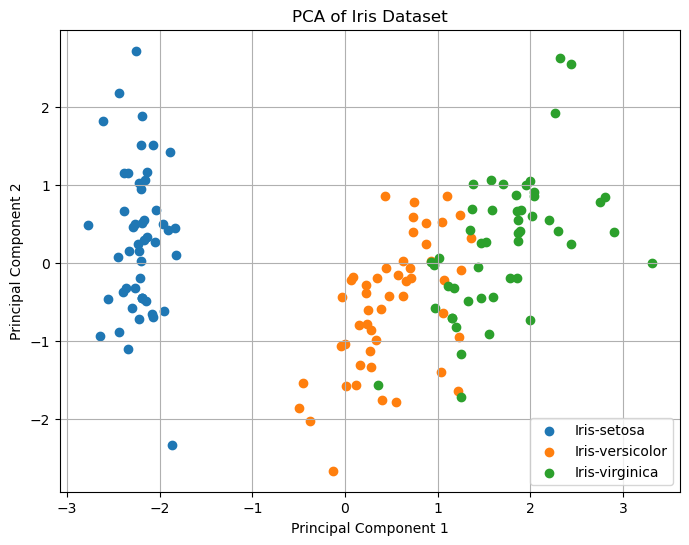

In [ ]:
plt.figure(figsize=(8, 6))
for species in pca_df["Species"].unique():
    subset = pca_df[pca_df["Species"] == species]
    
    plt.scatter(
        subset["Principal Component 1"],
        subset["Principal Component 2"],
        label=species
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Iris Dataset")
plt.legend()
plt.grid(True)

plt.show()

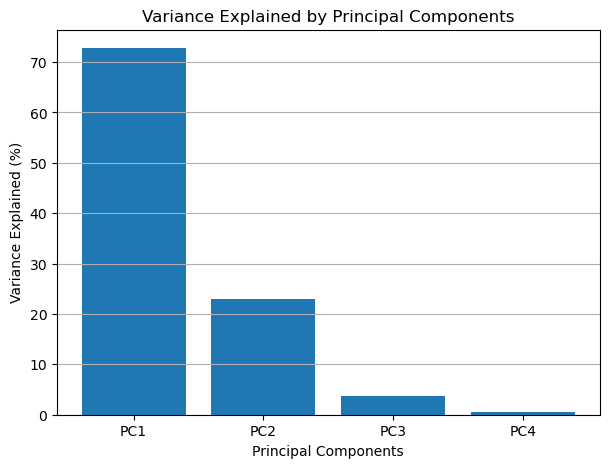

In [ ]:
pca_all = PCA(n_components=4)
pca_all.fit(X_scaled)

variance = pca_all.explained_variance_ratio_ * 100

plt.figure(figsize=(7, 5))

plt.bar(
    ["PC1", "PC2", "PC3", "PC4"],
    variance
)

plt.xlabel("Principal Components")
plt.ylabel("Variance Explained (%)")
plt.title("Variance Explained by Principal Components")
plt.grid(axis="y")

plt.show()

In [14]:
print("RESULT")
print("-" * 40)
print("Original number of features: 4")
print("Reduced number of features: 2")
print(f"PC1 variance: {pc1_variance:.2f}%")
print(f"PC2 variance: {pc2_variance:.2f}%")
print(f"Total variance retained: {total_variance:.2f}%")

RESULT
----------------------------------------
Original number of features: 4
Reduced number of features: 2
PC1 variance: 72.77%
PC2 variance: 23.03%
Total variance retained: 95.80%


In [16]:
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

In [17]:
# Load Mushroom Classification dataset
df = pd.read_csv("mushrooms.csv")

# Display first five rows
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (8124, 23)

Columns:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           81

In [19]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


In [20]:
# Create a copy of the dataset
df_encoded = df.copy()

# Encode all categorical columns
encoder = LabelEncoder()

for column in df_encoded.columns:
    df_encoded[column] = encoder.fit_transform(df_encoded[column])

# Display encoded data
df_encoded.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,1,5,2,4,1,6,1,0,1,4,...,2,7,7,0,2,1,4,2,3,5
1,0,5,2,9,1,0,1,0,0,4,...,2,7,7,0,2,1,4,3,2,1
2,0,0,2,8,1,3,1,0,0,5,...,2,7,7,0,2,1,4,3,2,3
3,1,5,3,8,1,6,1,0,1,5,...,2,7,7,0,2,1,4,2,3,5
4,0,5,2,3,0,5,1,1,0,4,...,2,7,7,0,2,1,0,3,0,1


In [ ]:
X = df_encoded.drop("class", axis=1)
y = df_encoded["class"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (8124, 22)
Target Shape: (8124,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (6499, 22)
Testing Data: (1625, 22)


In [23]:
# Create Naïve Bayes classifier
model = GaussianNB()

# Train the model
model.fit(X_train, y_train)

print("Naïve Bayes classifier trained successfully.")

Naïve Bayes classifier trained successfully.


In [24]:
# Predict the test data
y_pred = model.predict(X_test)

# Display first 20 predictions
print("Predicted Values:")
print(y_pred[:20])

print("\nActual Values:")
print(y_test.values[:20])

Predicted Values:
[1 1 0 1 1 0 0 0 0 1 1 1 1 0 0 1 1 0 1 0]

Actual Values:
[1 1 0 1 1 0 0 0 0 1 1 1 0 0 0 1 1 0 0 1]


In [ ]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.9286153846153846
Accuracy Percentage: 92.86153846153846 %


In [27]:
print("NAÏVE BAYES CLASSIFICATION RESULT")
print("Dataset Size:", df.shape)
print("Number of Features:", X.shape[1])
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print(f"Accuracy: {accuracy * 100:.2f}%")

NAÏVE BAYES CLASSIFICATION RESULT
Dataset Size: (8124, 23)
Number of Features: 22
Training Samples: 6499
Testing Samples: 1625
Accuracy: 92.86%
